<a href="https://colab.research.google.com/github/pramidi11/healthy-hello-app/blob/main/Assignment_copy_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSE5DL T3 Assignment

### Assignment due date: Sunday 14th of June 2026 by 11:59 pm (AEST/AEDT)

Penalties are applied to late assignments (accepted up to 5 business days after the due date only). Five percent is deducted per business day late. A mark of zero will be assigned to assignments submitted more than 5 days late.

<font color='red'> This is an individual assignment. You are not permitted to work as a part of a group when writing this assignment. </font>

### Assignment submission

Please zip all `*.ipynb`, `*.py`, `*.docx` and `*.xlsx` files into a single zip file and submit the zipped file via the link provided on LMS.

### Copying, Plagiarism
Plagiarism is the submission of somebody else’s work in a manner that gives the impression that the work is your own. For individual assignments, plagiarism includes the case where two or more students work collaboratively on the assignment.  The Department of Computer Science and Information Technology treats plagiarism very seriously.  When it is detected, penalties are strictly imposed.

## Generative AI Use

> ⚠️ **Important:** Do not ask AI to directly write your code. Doing so will deprive you of the chance to improve your coding skills. Instead, use AI to provide feedback on code *you* wrote. This way you struggle and learn while getting feedback to improve rapidly.

---

### ✅ Permitted AI Use

| Use Case | What's Allowed | What's NOT Allowed |
|----------|----------------|-------------------|
| **Code Review** | AI provides feedback on your code | AI writes or fixes code for you |
| **Report Writing** | AI polishes/refines text you wrote | AI adds new arguments or concepts |

> **Note:** Any AI-improved text must be critically reviewed before incorporating into your report.

---

### 📝 Required Prompts

Use the following prompts (or similar) when asking AI to review your work:

#### For Code Review:
> *"The following code block is for a Deep Learning Assessment Task. Critique the python code block provided. When providing feedback, do not generate any code and do not edit any of the provided code. You are only permitted to provide written feedback and suggestions to the student. Do not provide any feedback or suggestions on any task that the student has not attempted."*

#### For Report Review (Option 1 – Critique):
> *"The following text is part of a report for a Deep Learning Assessment Task. Critique the writing with a focus on readability and how effectively the student is communicating their ideas. You can provide feedback and suggestions on how to improve the writing. Do not provide any feedback on any task that the student has not attempted."*

#### For Report Review (Option 2 – Polish):
> *"The following text is part of a report for a Deep Learning Assessment Task. Please generate a more polished version of the writing with any spelling and grammar mistakes fixed, and improved flow of arguments. However, do not modify or add new arguments or concepts which do not currently exist. Do not provide any feedback on any task that the student has not attempted."*

---

### 📋 Requirements

- [ ] Provide evidence of AI usage in the **Evidence of AI Usage** word document
- [ ] Complete the **AI Acknowledgement** on the LMS when submitting

### Short Extension

This assessment is eligible for a short extension. Students may apply on the LMS for a short extension for this assessment

### Checklist of files you need to modify and submit
1. This ipynb notebook with the cells fill in.
2. Fill in the TODO code in the following python files:

    a. train.py

    b. models.py
     
    c. datasets.py
    
3. Filled in written report.
4. Wandb report (In PDF Format)
5. Excel spreadsheet with details of 10 model training runs for task 1g (similar to spreadsheet for lab 3).
6. The rest of .py files that you do not modify.
7. (If Applicable) Provide evidence of your AI Usage in the AI Usage word document
8. Complete the AI Acknowledgement on the LMS



# Introduction

**DESCRIPTION:** In this assignment we have provided you with skeleton code. You have an image dataset, and you must train a deep learning model for it. All of the code required has already been shown to you in the labs.

In this assignment you will be required to write code and write short answer responses to questions in a structured report. You have been provided with a template Word document of this report in which you simply have to fill in the blanks.


**INSTRUCTIONS:**

1.   Copy the skeleton files to your Google Drive.
2.   Edit `SKELETON_DIR` in the first cell to point to the skeleton files you uploaded in step 1. The provided code assumes you have uploaded them to "Uni/CSE3001/Assignment" in your Google Drive.
3.   Run the following two cells


In [2]:
from google.colab import drive
drive.mount('/content/drive')

# Set the working directory for the assignment
import os
SKELETON_DIR = '/content/drive/MyDrive/Uni/CSE3001/Assignment'
os.chdir(SKELETON_DIR)
! mkdir -p "$SKELETON_DIR/saved_models"
! mkdir -p "$SKELETON_DIR/logs"

# Import module for reloading code
import importlib

# Install extra dependencies
!pip install -q wandb==0.25.1
!pip install -q torchmetrics==0.11.3

# Set the default figure size
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 120

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.6/25.6 MB 80.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 518.6/518.6 kB 12.8 MB/s eta 0:00:00


In [3]:
%%shell
DATA_URL='https://latrobeuni-my.sharepoint.com/:u:/g/personal/zhe_ltu_edu_au/IQDZ9vv17l9qRqbTHx-nlSyKAT_r6iNISaVM_TP4SXH9iBw?e=XbB2Pa&download=1'

pushd /content
wget -O data.zip $DATA_URL
unzip -q data.zip
popd


/content /content/drive/MyDrive/Uni/CSE3001/Assignment
--2026-06-01 12:10:38--  https://latrobeuni-my.sharepoint.com/:u:/g/personal/zhe_ltu_edu_au/IQDZ9vv17l9qRqbTHx-nlSyKAT_r6iNISaVM_TP4SXH9iBw?e=XbB2Pa&download=1
Resolving latrobeuni-my.sharepoint.com (latrobeuni-my.sharepoint.com)... 13.107.136.10, 13.107.138.10, 2603:1061:13f2:2d10::365:590, ...
Connecting to latrobeuni-my.sharepoint.com (latrobeuni-my.sharepoint.com)|13.107.136.10|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: /personal/zhe_ltu_edu_au/Documents/CSE5DL%20data/data.zip?ga=1 [following]
--2026-06-01 12:10:39--  https://latrobeuni-my.sharepoint.com/personal/zhe_ltu_edu_au/Documents/CSE5DL%20data/data.zip?ga=1
Reusing existing connection to latrobeuni-my.sharepoint.com:443.
HTTP request sent, awaiting response... 200 OK
Length: 1043211099 (995M) [application/x-zip-compressed]
Saving to: ‘data.zip’

data.zip            100%[===================>] 994.88M  75.1MB/s    in 16s     

2026-06-0

# Task 1 - Image Classification

**MARKS**: 100

In this first task, you will create a deep learning model to classify images of skin lesions into one of seven classes:

1.   "MEL" = Melanoma
2.   "NV" = Melanocytic nevus
3.   "BCC" = Basal cell carcinoma
4.   "AKIEC" = Actinic keratosis
5.   "BKL" = Benign keratosis
6.   "DF" = Dermatofibroma
7.   "VASC" = Vascular lesion

The data for this task is a subset of: https://challenge2018.isic-archive.com/task3/

The data for this task is inside the `/content/data/img` folder. It contains ~3,800 images named like `ISIC_000000.jpg` and the following label files:

*   `/content/data/img/train.csv`
*   `/content/data/img/val.csv`
*   `/content/data/img/train_small.csv`
*   `/content/data/img/val_small.csv`

The `small` versions are the first 200 lines of each partition and are included for debugging purposes. To save time, ensure your code runs on the `small` versions first.

**NOTE**: To explore the labels, you can click the above hyperlinks to open the relevant csv file.

## Task 1a. Explore the training set

**MARKS**: 8 (Code 6, Reports 2)

**INSTRUCTIONS**: Check for data issues, as we have done in the labs. Check the class distribution and at least 1 other potential data issue. Hint: Look in `explore.py` for a function that can plot the class distribution.

**REPORT**: What data issues did you check for and why did you check for them? Make sure you check class distribution and at least 1 other potential data issue. Please report your findings.

**HINT**: This task primarily requires "PyTorch Basics" lab.

In [4]:
import pandas as pd

IMG_CLASS_NAMES = ["MEL", "NV", "BCC", "AKIEC", "BKL", "DF", "VASC"]

train_df = pd.read_csv('/content/data/img/train.csv')
val_df = pd.read_csv('/content/data/img/val.csv')
train_df.head()

,image,MEL,NV,BCC,AKIEC,BKL,DF,VASC
0,ISIC_0024306,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,ISIC_0024307,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,ISIC_0024308,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,ISIC_0024309,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,ISIC_0024310,1.0,0.0,0.0,0.0,0.0,0.0,0.0


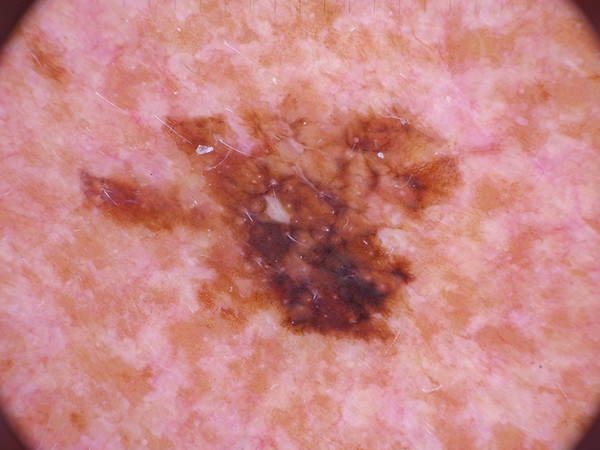

In [5]:
from PIL import Image
# Change the filename to view other examples from the dataset
display(Image.open('/content/data/img/ISIC_0024310.jpg'))

Train Labels (first 10):
 [1 1 1 1 0 1 4 0 1 0]
Train DataFrame (first 10 rows of labels):
    MEL   NV  BCC  AKIEC  BKL   DF  VASC
0  0.0  1.0  0.0    0.0  0.0  0.0   0.0
1  0.0  1.0  0.0    0.0  0.0  0.0   0.0
2  0.0  1.0  0.0    0.0  0.0  0.0   0.0
3  0.0  1.0  0.0    0.0  0.0  0.0   0.0
4  1.0  0.0  0.0    0.0  0.0  0.0   0.0
5  0.0  1.0  0.0    0.0  0.0  0.0   0.0
6  0.0  0.0  0.0    0.0  1.0  0.0   0.0
7  1.0  0.0  0.0    0.0  0.0  0.0   0.0
8  0.0  1.0  0.0    0.0  0.0  0.0   0.0
9  1.0  0.0  0.0    0.0  0.0  0.0   0.0

Train Label Distribution:


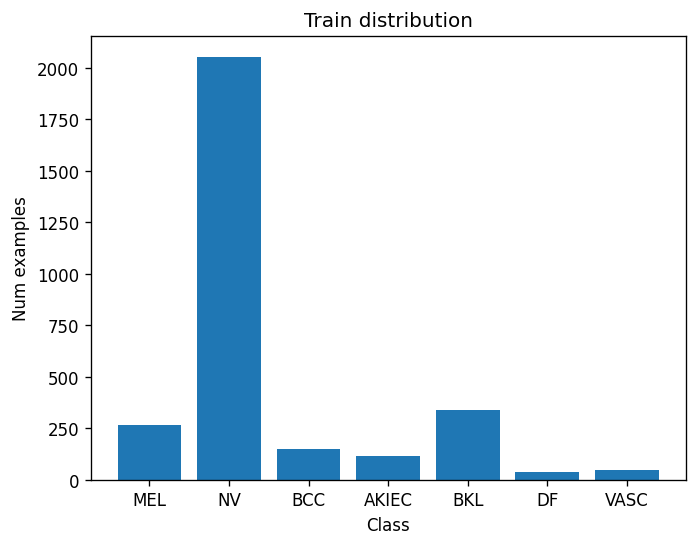


Validation Label Distribution:


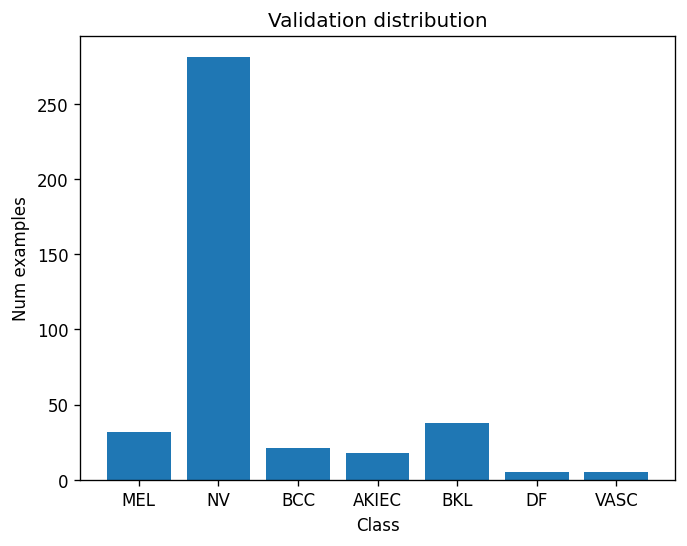

In [6]:
import explore
# Handle module reloading
importlib.reload(explore)

# TODO - Check for data issues
# Hint: You can convert from one-hot to integers with argmax
#       This way you can convert 1, 0, 0, 0, 0, 0, 0  to class 0
#                                0, 1, 0, 0, 0, 0, 0  to class 1
#                                0, 0, 1, 0, 0, 0, 0  to class 2
# so it should be something like the following:
# train_labels = train_df.values[....].argmax(....)
# val_labels = val_df.values[....].argmax(....)
#     - you need to fill in the ... parts with the correct values.
# You should then print output the contents of train_labels to see if
# it matches the contents of train.csv
#
# Next you can plot the class distributions like the following:
# explore.plot_label_distribution(....)
#    - do the above for both the train and val labels.
#
# Following this look for other potential problems with the data
#   You can look at lab 2a to see what was checked there.
#   You may also think of any other potential problems with the data.

# Convert from one-hot to integers with argmax
train_labels = train_df.iloc[:, 1:].values.argmax(axis=1)
val_labels = val_df.iloc[:, 1:].values.argmax(axis=1)

# Print the contents of train_labels to see if it matches the contents of train.csv
print("Train Labels (first 10):\n", train_labels[:10])
print("Train DataFrame (first 10 rows of labels):\n", train_df.iloc[:10, 1:])

# Plot the class distributions
print("\nTrain Label Distribution:")
explore.plot_label_distribution(train_labels, "Train", IMG_CLASS_NAMES)

print("\nValidation Label Distribution:")
explore.plot_label_distribution(val_labels, "Validation", IMG_CLASS_NAMES)

## Task 1b. Implement Training loop

**MARKS**: 24 (Code 20, Reports 4)

**INSTRUCTIONS**:

*   Implement LesionDataset in `datasets.py`. Use the cell below to test your implementation.
*   Implement the incomplete functions in `train.py` marked as "Task 1b"
*   Go to the [Model Training Cell](#task-1-model-training) at the end of Task 1 and fill in the required code for "Task 1b".

**REPORT**:
*   Q1. Why was the random_split function not used to create the train and validation splits?
*   Q2. How could you modify the training loop to only run a single batch for debugging purposes?

**HINT**: This task primarily requires "PyTorch Basics" lab.

In [7]:
import datasets
# Handle module reloading
importlib.reload(datasets)

ds = datasets.LesionDataset('/content/data/img',
                            '/content/data/img/train.csv')
input, label = ds[0]
print(input)
print(label)


tensor([[[ 1.7352,  1.7694,  1.8037,  ...,  1.7352,  1.7523,  1.7694],
         [ 1.7865,  1.8208,  1.8208,  ...,  1.7180,  1.7352,  1.7523],
         [ 1.8208,  1.7865,  1.7865,  ...,  1.7694,  1.7523,  1.7352],
         ...,
         [ 1.4612,  1.4612,  1.4269,  ...,  1.5125,  1.5468,  1.5125],
         [ 1.4612,  1.4783,  1.4783,  ...,  1.4954,  1.5297,  1.4954],
         [ 1.4440,  1.4440,  1.4612,  ...,  1.4612,  1.4612,  1.4783]],

        [[ 0.2227,  0.2577,  0.2577,  ...,  0.2752,  0.2927,  0.3277],
         [ 0.2402,  0.2577,  0.2927,  ...,  0.2927,  0.3277,  0.3277],
         [ 0.2577,  0.2577,  0.2577,  ...,  0.3452,  0.3452,  0.3277],
         ...,
         [ 0.0651,  0.0301, -0.0049,  ...,  0.4503,  0.4503,  0.4153],
         [ 0.0476,  0.0476,  0.0301,  ...,  0.4678,  0.4678,  0.4328],
         [ 0.0476,  0.0476,  0.0301,  ...,  0.4153,  0.4328,  0.4678]],

        [[ 0.4439,  0.4962,  0.5659,  ...,  0.4788,  0.5136,  0.5659],
         [ 0.4788,  0.5485,  0.6008,  ...,  0

[link text](https://)## Task 1c. Implement a baseline convolutional neural network

**MARKS**: 22 (Code 18, Reports 4)

You will implement a baseline convolutional neural network which you can compare results to. This allows you to evaluate any improvements made by hyperparameter tuning or transfer learning.

**INSTRUCTIONS**:

*   Implement a `SimpleBNConv` in `models.py` with:
    *   5 `nn.Conv2d` layers, with 8, 16, 32, 64, 128 output channels respectively, with the following between each convolution layer:
        *   `nn.ReLU()` for the activation function, and
        *   `nn.BatchNorm2d`, and
        *   finally a `nn.MaxPool2d` to downsample by a factor of 2.
*   Use a normalised confusion matrix on the model's validation predictions in `train.py`.
*  Go to the [Model Training Cell](#task-1-model-training) at the end of Task 1 and fill in the required code to train the model.

Training should take about 1 minute/epoch. Validation accuracy should be 60-70%, but UAR should be around 20-40%.

**REPORT**: Show the confusion matrix and metrics from your baseline CNN for each metric, explain what the confusion matrix and each metric is showing and what issues it may identify with the model.
(Right-click a plot and select "save image as..." to save the image to your computer)

**HINT**: This task primarily requires "Convolutional Neural Networks" lab.

## Task 1d. Account for data issues

**MARKS**: 12 (Code 8, Reports 4)

**INSTRUCTIONS**: Account for the data issues in Task 1a and retrain your model.

**REPORT**: Based on Task 1a, How did you account for the issues that you identified? Show evidence that your strategy has been successful (e.g. Provide a plot of a confusion matrix or one or more validation metrics similar to Task 1c)

**IMPORTANT NOTE**: One of the techniques from the lab will cause a warning in the metric calculation on `train_small.csv`, but will work fine on `train.csv`.

**HINT**: This task primarily requires "Debugging Neural Networks" lab.

## Task 1e. Data Augmentation

**MARKS**: 10 (Code 4, Reports 6)

**INSTRUCTIONS**:

*   Add an `augment` flag to LesionDataset which specifies whether any augmentation is done to the images. Ensure it is set to `True` *only* for the training dataset.
*   Use random horizontal flips
*   Use at least 2 other different non-deterministic augmentations

**REPORT:**
*   Q1. Are random vertical flips an appropriate augmentation for this dataset? Why or why not?
*   Q2. What data augmentations did you try and how did they affect the performance of the models? Provide relevant evidence such as Confusion Metrics, or one or more validation metrics

**HINT**: This task primarily requires "Image Augmentation" lab.

## Task 1f. Use a Pretrained Model

**MARKS** 8 (Code and reports not separable for this task)

**INSTRUCTIONS**
*   Create a model from a pre-trained model from the torchvision model zoo. We recommend Resnet18, but you may use any model you like. You may freeze the weights of all layers except the last, or fine-tune all the weights. https://docs.pytorch.org/vision/main/models.html
*  Create a table in an excel spreadsheet that is similar to that used in Lab 3 to record your results.
*  In addition to the excel spreadsheet generate a report using Weights and Biases of the models you trained and the performance curves. Save the report as a pdf and include this in your submission. Please see this link on how to generate reports with Weights and Biases. https://docs.wandb.ai/guides/reports


**REPORT**
*  Use a pretrained model from the Torchvision Model Zoo and compare the results of the following two transfer learning methods:
*  Freeze the weights of all of the layers except for the final linear layer
*  Fine-tune all of the weights of the model (Do not freeze any layers)

## Task 1g. Chase improved performance

**MARKS**: 16 (Code and reports not separable for this task)

**INSTRUCTIONS**:

* In this section conduct various experiments to improve the performance on the validation set, for each experiment consider one hyperparameter you want to tune (e.g. Learning Rate), during that experiment only adjust that one hyperparameter and perform several runs. You should run at least 3 experiments and have a total number of at least 10 runs across the experiments. Make sure to include at least two of  the following model variations: the models from task 1f and a new custom model architecture across your experiments. Record all of your runs in the spreadsheet created in Task 1f and include this task in the weights and biases report you created in Task 1f.

For each experiment record the following information in your Weights and Biases report

* Frame the experiment (Why do you think it could improve performance of the model?, how are you searching the hyperparameter (random, grid etc.))
* Perform the experiment (Do several runs)
* Evaluate the experiment (What is the outcome of your experiment? Did performance improve or not?)
* Inform future experiments (Draw a conclusion about the experiment additionally what have you learned from this outcome and how does it influence what you will try next?)

Please record all the configurations for the 10 runs in the excel spreadsheet. Here please write a list of findings from the experiments. For example, what was the effect of varying batch size, did higher learning rate hurt or improve performance, etc.

Finally, Please comment on which experiment was the most impactful.

**HINT**: The first part of this task primarily requires "Transfer Learning" lab.

<a name="task-1-model-training"></a>
## Model Training Cell

We will be using Weights and Biases to keep track of our experimental runs and evaluation metrics. The Weights and Biases tool is only used in "Text Sentiment Analysis" lab. If you have not completed this lab yet, you can get started with Weights and Biases by following Steps 1a), b) and c) from the following link: https://docs.wandb.ai/quickstart


Epochs:   0%|          | 0/5 [00:00<?, ?it/s]

Accuracy_train,▁▅▆▇█
Accuracy_val,▄▅▁▆█
Loss_train,█▄▃▂▁
Loss_val,▁▄█▁▃
UAR_train,▁▅▆▇█
UAR_val,▃█▄▁▅
Accuracy_train,0.85353
Accuracy_val,0.7
Loss_train,0.44022
Loss_val,1.05337
UAR_train,0.85236


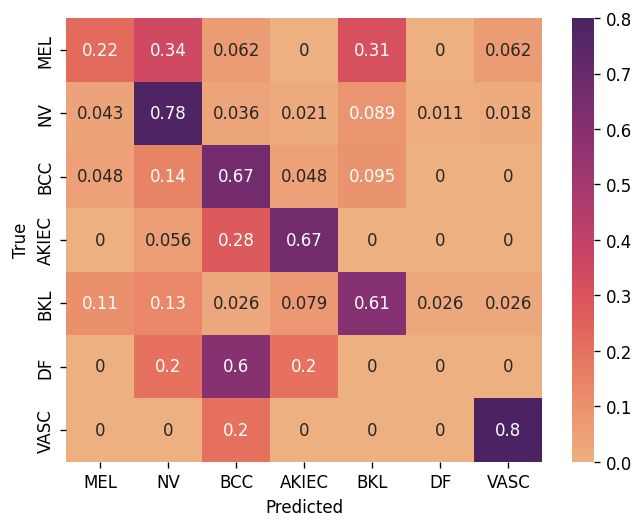

In [13]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torch.utils.data.sampler import WeightedRandomSampler

import datasets
import models
import train

# Handle module reloading
importlib.reload(datasets)
importlib.reload(models)
importlib.reload(train)

torch.manual_seed(42)

NUM_EPOCHS = 5
BATCH_SIZE = 64

# Create datasets/loaders
# TODO Task 1b - Create the data loaders from LesionDatasets
# TODO Task 1d - Account for data issues, if applicable

# Create datasets
train_dataset = datasets.LesionDataset('/content/data/img', '/content/data/img/train.csv')
val_dataset = datasets.LesionDataset('/content/data/img', '/content/data/img/val.csv')

# Calculate class weights for WeightedRandomSampler (Task 1d)
class_counts = torch.bincount(torch.tensor(train_labels))
class_weights = 1. / class_counts.float()
sample_weights = class_weights[train_labels]
sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

# Create data loaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=sampler)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

# Instantiate model, optimizer and criterion
# TODO Task 1c - Make an instance of your model
# TODO Task 1d - Account for data issues, if applicable
model = models.SimpleBNConv(num_classes=len(IMG_CLASS_NAMES))

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

# Train model
# TODO Task 1c: Set ident_str to a string that identifies this particular
#               training run. Note this line in the training code
#                     exp_name = f"{model.__class__.__name__}_{ident_str}"
#               So it means the the model class name is already included in the
#               exp_name string. You can consider adding other information
#               particular to this training run, e.g. learning rate (lr) used,
#               augmentation (aug) used or not, etc.

train.train_model(model, train_loader, val_loader, optimizer, criterion,
                  IMG_CLASS_NAMES, NUM_EPOCHS, project_name="CSE3001 Assignment Task 1",
                  ident_str= "baseline_no_aug")